# Finding similar movies from their plot summaries

Can a computer tell which films are alike just from reading their plots? This notebook takes the plot summaries of 100 well-known films (from IMDb and Wikipedia), turns them into TF-IDF vectors, and uses cosine similarity, k-means and hierarchical clustering to group films with similar stories.

In [1]:
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from nltk.stem.snowball import SnowballStemmer
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.spatial.distance import squareform
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

movies_df = pd.read_csv("datasets/movies.csv")
print("Number of movies:", len(movies_df))
movies_df.head()

Number of movies: 100


,rank,title,genre,wiki_plot,imdb_plot
0,0,The Godfather,"[u' Crime', u' Drama']","On the day of his only daughter's wedding, Vit...","In late summer 1945, guests are gathered for t..."
1,1,The Shawshank Redemption,"[u' Crime', u' Drama']","In 1947, banker Andy Dufresne is convicted of ...","In 1947, Andy Dufresne (Tim Robbins), a banker..."
2,2,Schindler's List,"[u' Biography', u' Drama', u' History']","In 1939, the Germans move Polish Jews into the...",The relocation of Polish Jews from surrounding...
3,3,Raging Bull,"[u' Biography', u' Drama', u' Sport']","In a brief scene in 1964, an aging, overweight...","The film opens in 1964, where an older and fat..."
4,4,Casablanca,"[u' Drama', u' Romance', u' War']",It is early December 1941. American expatriate...,"In the early years of World War II, December 1..."


## 1. Combine the two plot sources

Each film has a Wikipedia plot and, for most, an IMDb plot. Joining them gives the vectoriser more text per film. Missing IMDb plots are treated as empty strings.

In [2]:
print("Missing plots:\n", movies_df[["wiki_plot", "imdb_plot"]].isna().sum())

movies_df["plot"] = movies_df["wiki_plot"].fillna("") + "\n" + movies_df["imdb_plot"].fillna("")
movies_df["plot"].str.split().str.len().describe().round(0)

Missing plots:
 wiki_plot     0
imdb_plot    10
dtype: int64


count     100.0
mean     3101.0
std      1388.0
min       571.0
25%      2274.0
50%      2757.0
75%      3768.0
max      7686.0
Name: plot, dtype: float64

## 2. Tokenise and stem

Each plot is lower-cased and split into alphabetic words, and every word is reduced to its stem with the Snowball stemmer, so that "wedding", "weddings" and "wed" count as the same term.

In [3]:
stemmer = SnowballStemmer("english")


def tokenize_and_stem(text):
    """Split text into alphabetic tokens and return their stems."""
    tokens = re.findall(r"[a-z]+(?:'[a-z]+)?", text.lower())
    return [stemmer.stem(token) for token in tokens]


print(tokenize_and_stem("Today (May 19, 2016) is his only daughter's wedding."))

['today', 'may', 'is', 'his', 'onli', 'daughter', 'wed']


## 3. TF-IDF vectors

TF-IDF weights a term highly when it is frequent in one plot but rare across the others. Terms that appear in more than 80% of plots or fewer than 20% are dropped, and one- to three-word phrases are included. The stop-word list is stemmed too, so it matches the stemmed tokens.

In [4]:
stemmed_stop_words = sorted({stemmer.stem(word) for word in ENGLISH_STOP_WORDS})

tfidf_vectorizer = TfidfVectorizer(max_df=0.8, min_df=0.2, stop_words=stemmed_stop_words,
                                   tokenizer=tokenize_and_stem, token_pattern=None, ngram_range=(1, 3))
tfidf_matrix = tfidf_vectorizer.fit_transform(movies_df["plot"])

print("Matrix shape (movies, terms):", tfidf_matrix.shape)
print("Sample terms:", list(tfidf_vectorizer.get_feature_names_out()[:15]))

Matrix shape (movies, terms): (100, 537)
Sample terms: ['abandon', 'abl', 'accept', 'accid', 'accompani', 'accus', 'act', 'action', 'actual', 'admit', 'age', 'ago', 'agre', 'aid', 'air']


## 4. K-means clusters

Five clusters, with a fixed seed so the result is reproducible.

In [5]:
km = KMeans(n_clusters=5, n_init=10, random_state=5)
movies_df["cluster"] = km.fit_predict(tfidf_matrix)
movies_df["cluster"].value_counts().sort_index()

cluster
0    34
1     6
2    21
3    29
4    10
Name: count, dtype: int64

The highest-weighted terms at each cluster centre, with a few example films:

In [6]:
terms = tfidf_vectorizer.get_feature_names_out()
order = km.cluster_centers_.argsort()[:, ::-1]

for cluster in range(5):
    top_terms = ", ".join(terms[i] for i in order[cluster, :8])
    examples = ", ".join(movies_df.loc[movies_df["cluster"] == cluster, "title"].head(5))
    print(f"Cluster {cluster}\n  terms:  {top_terms}\n  movies: {examples}\n")

Cluster 0
  terms:  car, hous, mother, polic, mr, home, kill, run
  movies: Citizen Kane, The Wizard of Oz, Titanic, Psycho, Sunset Blvd.

Cluster 1
  terms:  georg, marri, woman, famili, friend, john, jame, play
  movies: It's a Wonderful Life, The Philadelphia Story, An American in Paris, The King's Speech, A Place in the Sun

Cluster 2
  terms:  famili, father, war, son, brother, captain, sister, kill
  movies: The Godfather, Raging Bull, Gone with the Wind, The Godfather: Part II, The Sound of Music

Cluster 3
  terms:  kill, say, friend, polic, fight, murder, love, apart
  movies: The Shawshank Redemption, Casablanca, One Flew Over the Cuckoo's Nest, Vertigo, On the Waterfront

Cluster 4
  terms:  soldier, command, war, armi, general, kill, men, offic
  movies: Schindler's List, Lawrence of Arabia, The Bridge on the River Kwai, Dr. Strangelove or: How I Learned to Stop Worrying and Love the Bomb, Apocalypse Now



## 5. Pairwise similarity

Cosine similarity between TF-IDF vectors is 1 for identical term profiles and 0 when two plots share no terms. The helper below looks up the closest matches for any title.

In [7]:
similarity = cosine_similarity(tfidf_matrix)
similarity_df = pd.DataFrame(similarity, index=movies_df["title"], columns=movies_df["title"])


def most_similar(title, n=5):
    """Return the n films whose plots are most similar to the given title."""
    return similarity_df[title].drop(title).nlargest(n).round(3)


for title in ["The Godfather", "Star Wars", "Braveheart"]:
    print(title)
    print(most_similar(title, 3).to_string(), "\n")

The Godfather
title
The Godfather: Part II    0.641
Goodfellas                0.522
Giant                     0.472 

Star Wars
title
2001: A Space Odyssey                 0.468
Raiders of the Lost Ark               0.409
Close Encounters of the Third Kind    0.377 

Braveheart
title
Gladiator             0.448
Gone with the Wind    0.383
The Godfather         0.338 



## 6. Hierarchical clustering

A dendrogram shows the whole similarity structure at once. Films that merge low down in the tree have the most similar plots. The distance used is `1 - cosine similarity`, with complete linkage.

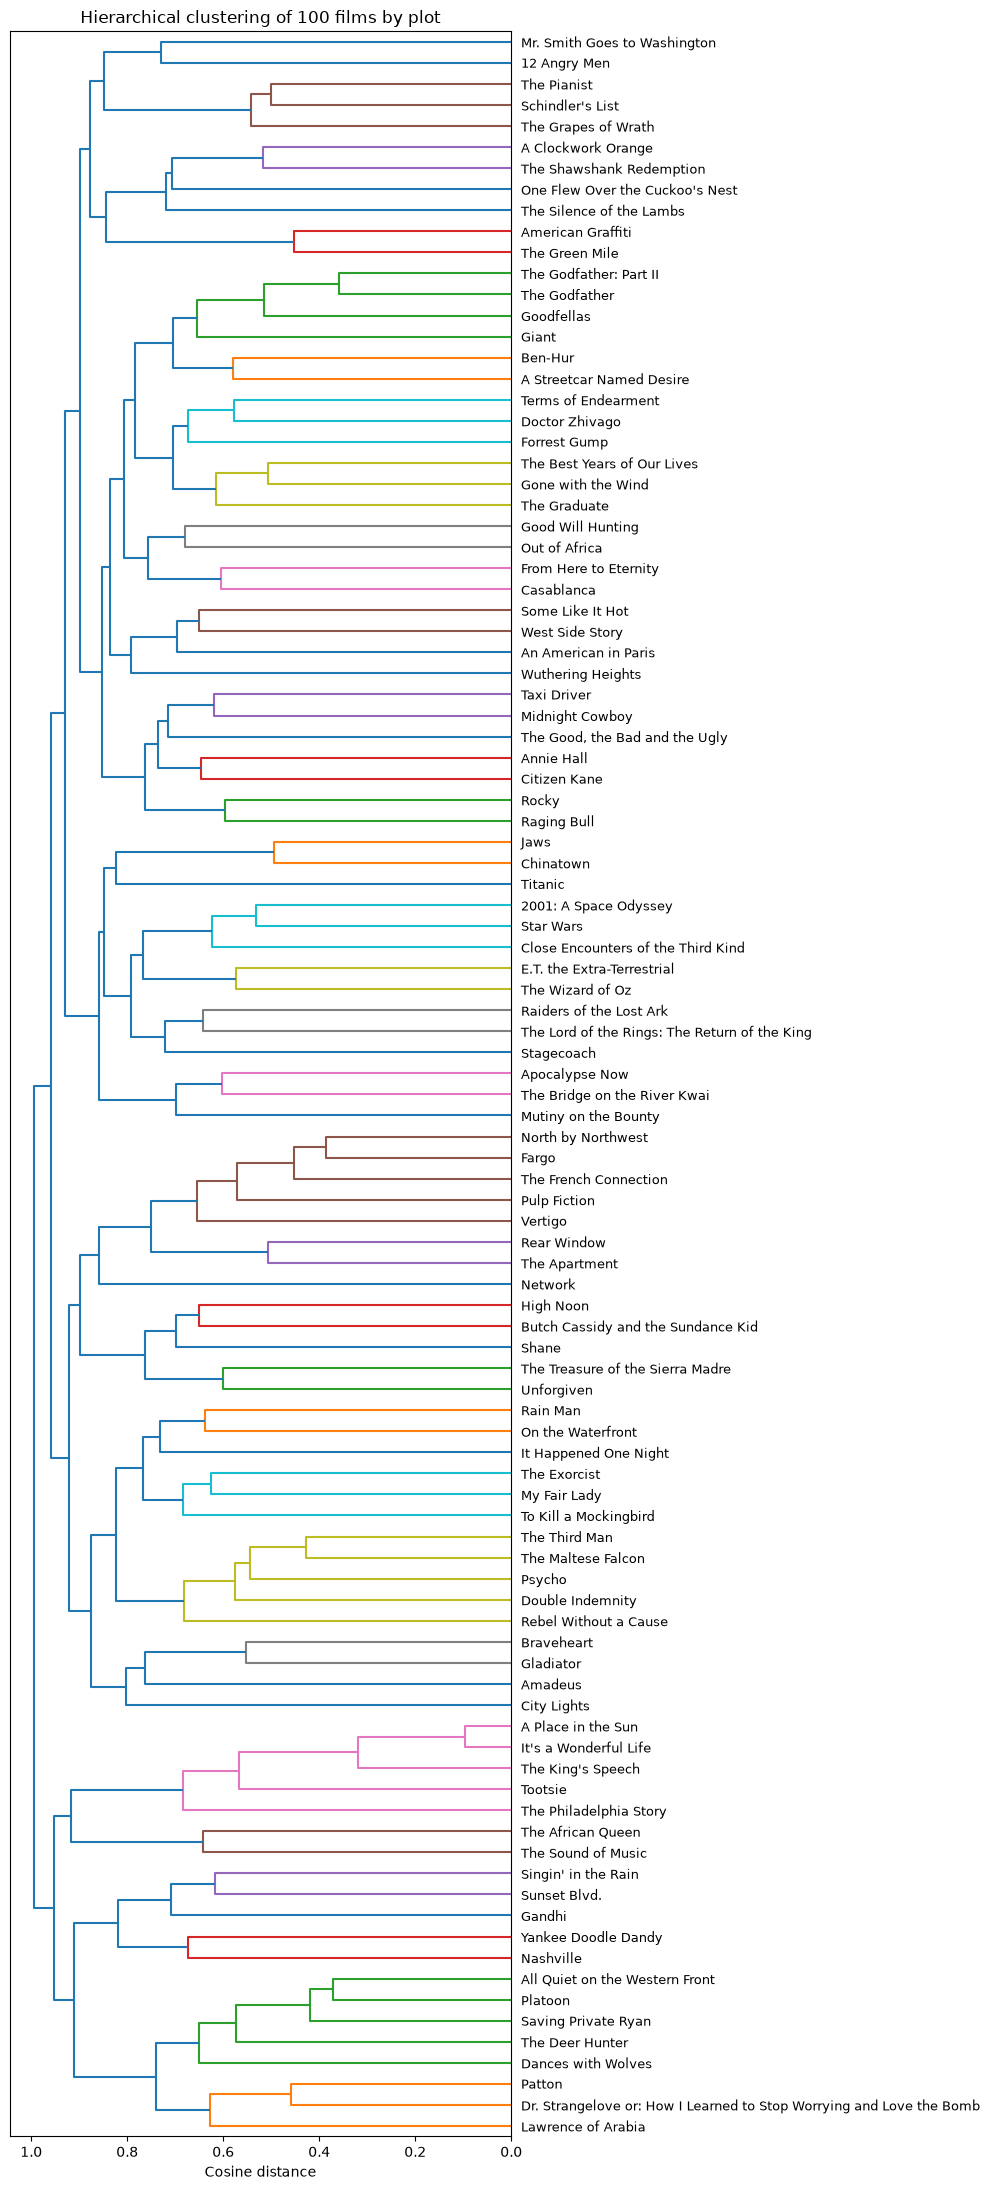

In [8]:
distance = 1 - similarity
np.fill_diagonal(distance, 0)
mergings = linkage(squareform(distance, checks=False), method="complete")

fig, ax = plt.subplots(figsize=(10, 22))
dendrogram(mergings, labels=movies_df["title"].tolist(), orientation="left", leaf_font_size=9, ax=ax)
ax.set_xlabel("Cosine distance")
ax.set_title("Hierarchical clustering of 100 films by plot")
plt.tight_layout()
plt.show()

## 7. The most similar pairs

In [9]:
pairs = similarity_df.where(np.triu(np.ones(similarity_df.shape, dtype=bool), k=1)).stack()
pairs.index.names = ["movie_a", "movie_b"]
pairs.sort_values(ascending=False).head(10).round(3).rename("cosine_similarity").reset_index()

,movie_a,movie_b,cosine_similarity
0,It's a Wonderful Life,A Place in the Sun,0.904
1,It's a Wonderful Life,The King's Speech,0.705
2,The King's Speech,A Place in the Sun,0.681
3,The Godfather,The Godfather: Part II,0.641
4,Platoon,All Quiet on the Western Front,0.629
5,Saving Private Ryan,Platoon,0.618
6,Fargo,North by Northwest,0.614
7,Saving Private Ryan,All Quiet on the Western Front,0.580
8,The French Connection,North by Northwest,0.576
9,The Maltese Falcon,The Third Man,0.572


## Findings

- The approach picks up sensible matches with no knowledge of genre: *The Godfather* pairs with *The Godfather: Part II* and *Goodfellas*, *Braveheart* with *Gladiator*, and the war films (*Platoon*, *Saving Private Ryan*, *All Quiet on the Western Front*) all land close together.
- The single most similar pair, *It's a Wonderful Life* and *A Place in the Sun* (0.90), is a false positive. The two stories have little in common, but both leads are called George, and *The King's Speech* (George VI) joins them for the same reason. Character names carry a lot of TF-IDF weight because they are frequent in one plot and rare elsewhere.
- The k-means clusters are harder to interpret than the pairwise results. With 100 films and plots of very different lengths, the cluster sizes are uneven and the top terms are mostly generic story words.

Improvements worth trying: remove person names before vectorising (for example with named-entity recognition), and compare against sentence embeddings, which capture meaning rather than shared vocabulary.